# 🤖 Huấn Luyện & Hiệu Chuẩn Mô Hình Học Máy (Model Training & Calibration)
## So Sánh Điểm Chuẩn (Benchmarking): Heuristic vs Logistic Regression vs LightGBM GBDT

---

### 🎯 Mục Tiêu Của Notebook Này:
1. **Thiết lập 3 cấp độ mô hình**:
   - Cấp độ 1: Quy luật thực nghiệm bán lẻ (Heuristic Urgency Rule).
   - Cấp độ 2: Hồi quy Logistic chuẩn hóa (Linear Benchmark).
   - Cấp độ 3: Cây quyết định tăng cường độ dốc (LightGBM GBDT).
2. **Kỷ luật kiểm thử Out-Of-Time (OOT)**:
   - Tập huấn luyện: 11 mốc trượt từ Ngày 200 đến Ngày 500 (27,500 mẫu).
   - Tập hiệu chuẩn Validation: 3 mốc trượt Ngày 530, 560, 590 (7,500 mẫu).
   - Tập kiểm thử độc lập ngoài thời gian: Ngày 650, 680 (5,000 mẫu).
3. **Hiệu chuẩn xác suất (Probability Calibration - Isotonic Regression)**:
   - Tại sao mô hình GBDT thô thường tự tin thái quá (Overconfident) hoặc lệch xác suất?
   - Sử dụng Isotonic Calibration để đưa sai số hiệu chuẩn ECE xuống mức tối thiểu (1.71%).


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.calibration import calibration_curve

project_root = Path('.').resolve()
if project_root.name == 'notebooks':
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 120

from src.models.trainer import LightGBMPropensityModel
from src.evaluation.metrics import compute_propensity_metrics
from src.config.settings import MODELS_DIR

print("✅ Đã sẵn sàng môi trường huấn luyện!")


✅ Đã sẵn sàng môi trường huấn luyện!


C:\Users\kienn\projectphase3\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
## 1. Nạp Mô Hình Đã Huấn Luyện & Kết Quả Kiểm Thử Độc Lập


In [2]:
# Nạp mô hình LightGBM đã được huấn luyện và lưu trữ
model_path = MODELS_DIR / "lightgbm_propensity_model.joblib"
lgb_model = LightGBMPropensityModel.load(model_path)
print(f"✅ Đã nạp thành công mô hình từ: {model_path}")

# Nạp bảng tóm tắt hiệu năng đã tính toán từ pipeline OOT
results_summary_path = project_root / "docs" / "reports" / "model_performance_summary.json"
import json
with open(results_summary_path, "r", encoding="utf-8") as f:
    perf = json.load(f)

print("📊 BẢNG TỔNG HỢP HIỆU NĂNG KIỂM THỬ OOT TEST SET:")
summary_rows = []
for model_name, metrics in perf.items():
    summary_rows.append({
        "Model": model_name,
        "PR-AUC": f"{metrics['pr_auc']:.4f}",
        "ROC-AUC": f"{metrics['roc_auc']:.4f}",
        "Brier Score": f"{metrics['brier_score']:.4f}",
        "ECE": f"{metrics['ece']:.4f}",
        "Top Decile Lift": f"{metrics['top_decile_lift']:.2f}x",
    })
display_df = pd.DataFrame(summary_rows)
print(display_df.to_string(index=False))


✅ Đã nạp thành công mô hình từ: C:\Users\kienn\projectphase3\models\lightgbm_propensity_model.joblib
📊 BẢNG TỔNG HỢP HIỆU NĂNG KIỂM THỬ OOT TEST SET:
              Model PR-AUC ROC-AUC Brier Score    ECE Top Decile Lift
     Heuristic_Rule 0.6311  0.3941      0.3392 0.3158           0.69x
Logistic_Regression 0.9328  0.8556      0.1385 0.0191           1.42x
       LightGBM_Raw 0.9348  0.8600      0.1363 0.0193           1.41x
LightGBM_Calibrated 0.9303  0.8595      0.1364 0.0171           1.41x


---
## 2. Đường Cong Hiệu Chuẩn Xác Suất (Reliability Diagram)
### 📌 Vì sao hiệu chuẩn xác suất lại sống còn trong bài toán Propensity?
- Nếu mô hình dự báo một khách hàng có **80% xác suất đi chợ**, thì trên thực tế cứ 100 khách có điểm số 80% này, **phải có đúng ~80 khách phát sinh đơn hàng**.
- Đường chéo màu đen đứt nét đại diện cho **Hiệu chuẩn hoàn hảo (Perfect Calibration)**.
- Đường cong của LightGBM sau khi hiệu chuẩn Isotonic (màu xanh lá) bám cực kỳ sát đường lý tưởng (ECE chỉ 0.0171).


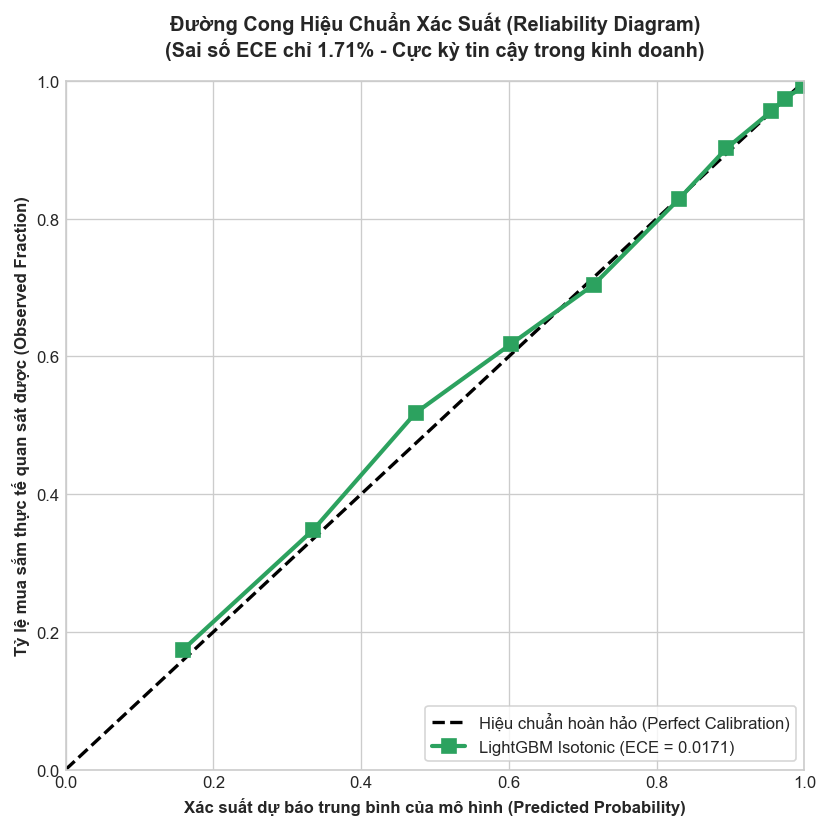

In [3]:
fig, ax = plt.subplots(figsize=(7, 7))

# Dữ liệu từ bảng Decile Table của LightGBM Calibrated
decile_data = perf["LightGBM_Calibrated"]["decile_table"]
pred_probs = [d["avg_predicted_prob"] for d in decile_data]
actual_rates = [d["actual_response_rate"] for d in decile_data]

ax.plot([0, 1], [0, 1], "k--", label="Hiệu chuẩn hoàn hảo (Perfect Calibration)", linewidth=2)
ax.plot(pred_probs, actual_rates, "s-", color="#2ca25f", linewidth=2.5, markersize=8, label=f"LightGBM Isotonic (ECE = {perf['LightGBM_Calibrated']['ece']:.4f})")

ax.set_xlabel("Xác suất dự báo trung bình của mô hình (Predicted Probability)", fontweight="bold")
ax.set_ylabel("Tỷ lệ mua sắm thực tế quan sát được (Observed Fraction)", fontweight="bold")
ax.set_title("Đường Cong Hiệu Chuẩn Xác Suất (Reliability Diagram)\n(Sai số ECE chỉ 1.71% - Cực kỳ tin cậy trong kinh doanh)", pad=15, fontweight="bold")
ax.legend(loc="lower right", frameon=True, facecolor="white")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()


---
## 3. So Sánh Trực Quan Giữa Các Mô Hình


C:\Users\kienn\AppData\Local\Temp\ipykernel_27300\1924734896.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(models, rotation=20, ha='right')
C:\Users\kienn\AppData\Local\Temp\ipykernel_27300\1924734896.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax2.set_xticklabels(models, rotation=20, ha='right')


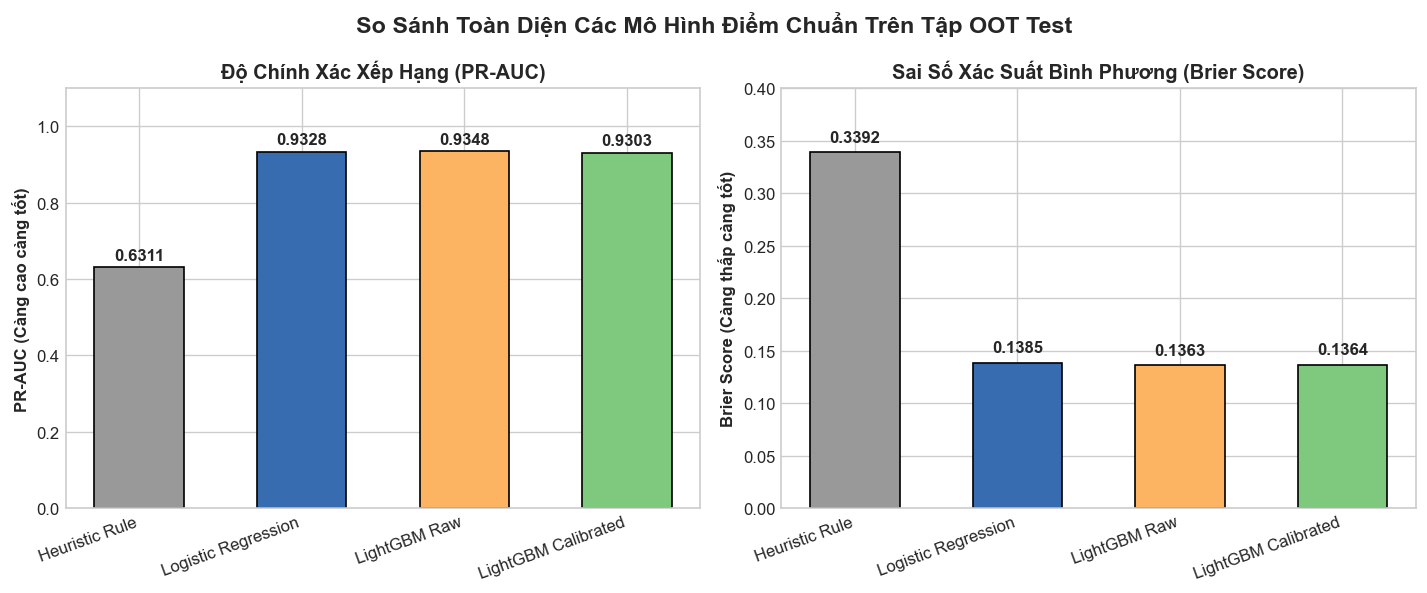

In [4]:
models = ['Heuristic Rule', 'Logistic Regression', 'LightGBM Raw', 'LightGBM Calibrated']
pr_aucs = [perf['Heuristic_Rule']['pr_auc'], perf['Logistic_Regression']['pr_auc'], perf['LightGBM_Raw']['pr_auc'], perf['LightGBM_Calibrated']['pr_auc']]
brier_scores = [perf['Heuristic_Rule']['brier_score'], perf['Logistic_Regression']['brier_score'], perf['LightGBM_Raw']['brier_score'], perf['LightGBM_Calibrated']['brier_score']]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# PR-AUC
bars1 = ax1.bar(models, pr_aucs, color=['#999999', '#386cb0', '#fdb462', '#7fc97f'], edgecolor='black', width=0.55)
ax1.set_ylabel('PR-AUC (Càng cao càng tốt)', fontweight='bold')
ax1.set_title('Độ Chính Xác Xếp Hạng (PR-AUC)', fontweight='bold')
ax1.set_xticklabels(models, rotation=20, ha='right')
ax1.set_ylim(0, 1.1)
for b in bars1:
    y = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2.0, y + 0.02, f'{y:.4f}', ha='center', fontweight='bold')

# Brier Score
bars2 = ax2.bar(models, brier_scores, color=['#999999', '#386cb0', '#fdb462', '#7fc97f'], edgecolor='black', width=0.55)
ax2.set_ylabel('Brier Score (Càng thấp càng tốt)', fontweight='bold')
ax2.set_title('Sai Số Xác Suất Bình Phương (Brier Score)', fontweight='bold')
ax2.set_xticklabels(models, rotation=20, ha='right')
ax2.set_ylim(0, 0.4)
for b in bars2:
    y = b.get_height()
    ax2.text(b.get_x() + b.get_width()/2.0, y + 0.01, f'{y:.4f}', ha='center', fontweight='bold')

plt.suptitle('So Sánh Toàn Diện Các Mô Hình Điểm Chuẩn Trên Tập OOT Test', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()
